In [1]:
import numpy as np
import sys
import os

sys.path.append(os.path.abspath(".."))

from class_particle_filter import BootstrapParticleFilter
from simulations import system_simulation
from plot import plot_results, plot_sorted_weights

# ESTUDIO DEGENERACION DE PESOS

En este script se estudia la degeneración de pesos a partir de un sistema lineal.

Estado:

$$
x_t = A x_{t-1} + w_t, \;\;\; w_t \sim N(0,Q)
$$

Observación:
$$
y_t = H x_t + v_t, \;\;\; v_t \sim N(0,R)
$$

donde

### Ejemplo 1D

$$
A = [1.0] \;\;\; H=[1.0] \;\;\; Q=[0.1] \;\;\; R = [0.5]
$$

### CASO SIN REMUESTREO

In [24]:
# Modelo lineal 1D
A = np.array([[1.0]])
H = np.array([[1.0]])   # observación directa

Q = 0.1  # ruido proceso
R = 0.5  # ruido observación

def f(x):
    return A @ x

def h(x):
    return H @ x

In [25]:
#Simulacion
T = 500
x0 = np.array([0.0])

x_true, y_obs = system_simulation(A, H, Q, R, x0, T)

In [26]:
# Inicialización Bootstrap Particle Filter
pf = BootstrapParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0]), cov=np.array([[1.0]]))

In [27]:
# Ejecutra filtro de partículas
est = pf.run_filter(y_obs)

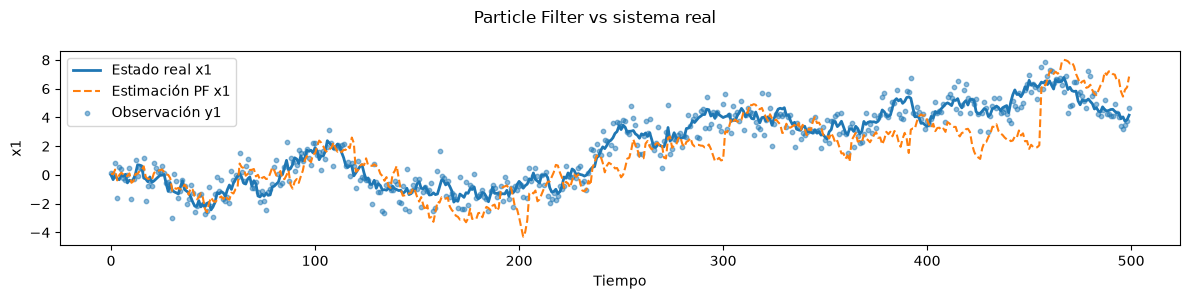

In [28]:
# Plotear resultados
x_est = est["estimates"]

plot_results(x_true, y_obs, x_est)

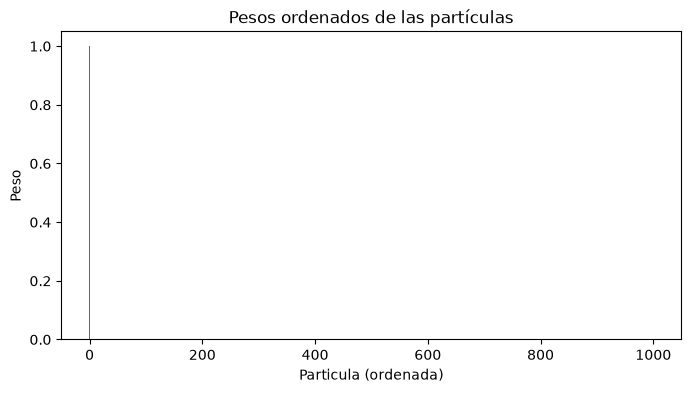

In [29]:
# Plotear pesos de las particulas
weights = est["weights"]

plot_sorted_weights(weights[-1])


### CASO CON REMUESTREO

In [30]:
# Inicialización Bootstrap Particle Filter
pf = BootstrapParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0]), cov=np.array([[1.0]]))

In [31]:
# Ejecutra filtro de partículas con resampling
est = pf.run_filter(y_obs, resample_threshold=500)

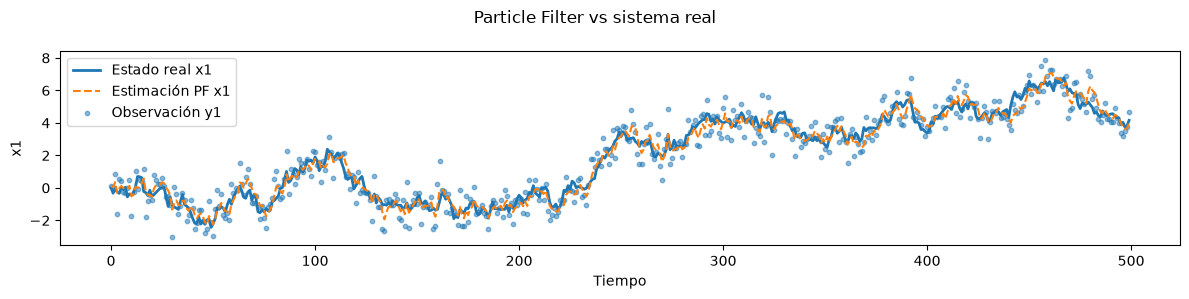

In [32]:
# Plotear resultados
x_est = est["estimates"]

plot_results(x_true, y_obs, x_est)

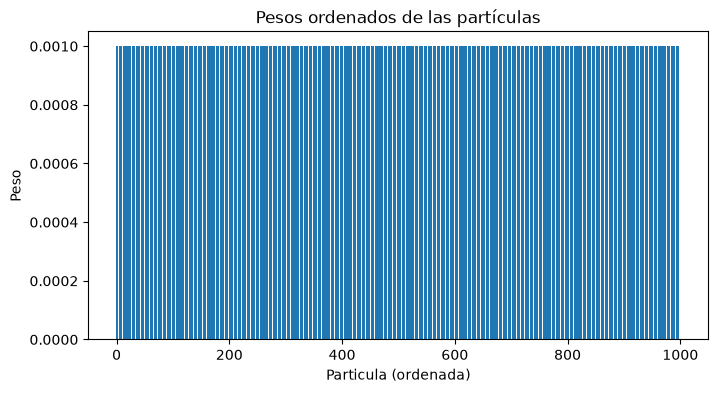

In [33]:
# Plotear pesos de las particulas
weights = est["weights"]

plot_sorted_weights(weights[-1])